In [4]:
# 1. Import Library & Load Dataset
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import LabelEncoder
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

dataset_path = 'dataset/index_data.csv' if os.path.exists('dataset/index_data.csv') else '../dataset/index_data.csv'
df = pd.read_csv(dataset_path)
print(f'Data berhasil dimuat: {df.shape[0]} baris, {df.shape[1]} kolom')
df.head()

Data berhasil dimuat: 1765 baris, 9 kolom


,Nama Suami,Nama Istri,Usia Suami,Usia Istri,Pendidikan Suami,Pendidikan Istri,Pekerjaan Suami,Pekerjaan Istri,Tahun
0,DEDE IRSAN,PUJI WIDIASTUTI,27,24,SLTP/SEDERAJAT,SLTA/SEDERAJAT,PELAJAR / MAHASISWA,PELAJAR / MAHASISWA,2021
1,SUPRIATNA MOCHAMMAD SAMAWI,SUSANTI,24,20,SLTA/SEDERAJAT,SLTP/SEDERAJAT,PELAJAR / MAHASISWA,PELAJAR / MAHASISWA,2021
2,SUHENDI,ELA LAELAWATI,40,39,SLTP/SEDERAJAT,SLTP/SEDERAJAT,WIRASWASTA,MENGURUS RUMAH TANGGA,2021
3,ARI HANA SUPARMAN,ANAH SUMIANGSIH,31,26,SLTA/SEDERAJAT,TAMAT SD/SEDERAJATNYA,BELUM / TIDAK BEKERJA,PELAJAR / MAHASISWA,2021
4,UJANG ALI ROHMAN,SITI HILMAH SHOFIYAH,24,21,SLTA/SEDERAJAT,TAMAT SD/SEDERAJATNYA,BELUM / TIDAK BEKERJA,BELUM / TIDAK BEKERJA,2021


In [5]:
# 2. Preprocessing Data & Penentuan Label Target
# Koreksi anomali usia 0 (kasus typo KUA)
df.loc[df['Usia Istri'] == 0, 'Usia Istri'] = 20

# Imputasi missing values pada kolom pendidikan
df['Pendidikan Suami'] = df['Pendidikan Suami'].fillna('TIDAK DIKETAHUI')
df['Pendidikan Istri'] = df['Pendidikan Istri'].fillna('TIDAK DIKETAHUI')

# Penentuan Label Target Klasifikasi:
# Kategori Kelayakan Usia Pernikahan (Standar Usia Matang BKKBN: Suami >= 19 th, Istri >= 19 th)
# *Catatan: Jika skripsi Anda menggunakan kolom/aturan label lain, sesuaikan baris di bawah ini:
df['Status_Kelayakan'] = np.where(
    (df['Usia Suami'] >= 19) & (df['Usia Istri'] >= 19),
    'Ideal',
    'Kurang Ideal'
)

print('Distribusi Kelas Target:')
print(df['Status_Kelayakan'].value_counts())
print(f"Persentase:\n{df['Status_Kelayakan'].value_counts(normalize=True) * 100}")

Distribusi Kelas Target:
Status_Kelayakan
Ideal           1732
Kurang Ideal      33
Name: count, dtype: int64
Persentase:
Status_Kelayakan
Ideal           98.130312
Kurang Ideal     1.869688
Name: proportion, dtype: float64


In [6]:
# 3. Encoding Fitur Kategorikal
categorical_cols = ['Pendidikan Suami', 'Pendidikan Istri', 'Pekerjaan Suami', 'Pekerjaan Istri']
encoders = {}

for col in categorical_cols:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])
    encoders[col] = le

# Tentukan fitur (X) dan target (y)
features = ['Usia Suami', 'Usia Istri', 'Pendidikan Suami', 'Pendidikan Istri', 'Pekerjaan Suami', 'Pekerjaan Istri', 'Tahun']
X = df[features]
y = df['Status_Kelayakan']

print('Fitur yang digunakan:', features)
X.head()

Fitur yang digunakan: ['Usia Suami', 'Usia Istri', 'Pendidikan Suami', 'Pendidikan Istri', 'Pekerjaan Suami', 'Pekerjaan Istri', 'Tahun']


,Usia Suami,Usia Istri,Pendidikan Suami,Pendidikan Istri,Pekerjaan Suami,Pekerjaan Istri,Tahun
0,27,24,5,4,13,11,2021
1,24,20,4,5,13,11,2021
2,40,39,5,5,27,9,2021
3,31,26,4,10,0,11,2021
4,24,21,4,10,0,1,2021


In [7]:
# 4. Split Data Latih & Data Uji (80:20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f'Jumlah Data Latih (Training): {len(X_train)} baris')
print(f'Jumlah Data Uji (Testing)   : {len(X_test)} baris')

Jumlah Data Latih (Training): 1412 baris
Jumlah Data Uji (Testing)   : 353 baris


In [8]:
# 5. Training Model Naive Bayes
nb_model = GaussianNB()
nb_model.fit(X_train, y_train)
print('Model Naive Bayes berhasil dilatih!')

Model Naive Bayes berhasil dilatih!


In [9]:
# 6. Evaluasi Model (Akurasi, Confusion Matrix, Classification Report)
y_pred = nb_model.predict(X_test)

acc = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred, labels=['Ideal', 'Kurang Ideal'])

print('================ HASIL EVALUASI MODEL ================')
print(f'Akurasi: {acc * 100:.2f}%\n')
print('Confusion Matrix:')
print(cm)
print('\nClassification Report:')
print(classification_report(y_test, y_pred))

================ HASIL EVALUASI MODEL ================
Akurasi: 96.32%

Confusion Matrix:
[[334  12]
 [  1   6]]

Classification Report:
              precision    recall  f1-score   support

       Ideal       1.00      0.97      0.98       346
Kurang Ideal       0.33      0.86      0.48         7

    accuracy                           0.96       353
   macro avg       0.67      0.91      0.73       353
weighted avg       0.98      0.96      0.97       353



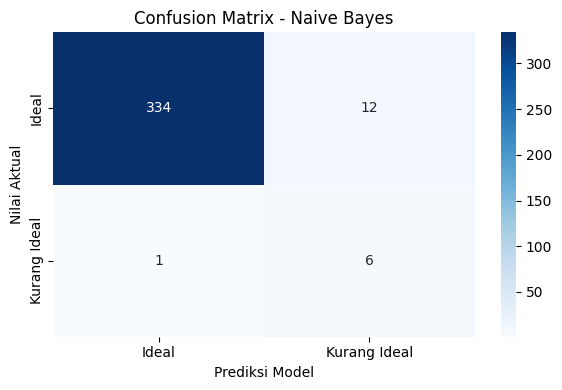

In [10]:
# 7. Visualisasi Confusion Matrix
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Ideal', 'Kurang Ideal'],
            yticklabels=['Ideal', 'Kurang Ideal'])
plt.title('Confusion Matrix - Naive Bayes')
plt.xlabel('Prediksi Model')
plt.ylabel('Nilai Aktual')
plt.tight_layout()
plt.show()

In [11]:
# 8. 10-Fold Cross Validation
cv_scores = cross_val_score(nb_model, X, y, cv=10, scoring='accuracy')

print('Skor Akurasi 10-Fold CV:')
for i, score in enumerate(cv_scores, 1):
    print(f'  Fold {i:2d}: {score * 100:.2f}%')

print(f'\nRata-rata Akurasi (Mean CV): {cv_scores.mean() * 100:.2f}% (+/- {cv_scores.std() * 100:.2f}%)')

Skor Akurasi 10-Fold CV:
  Fold  1: 94.35%
  Fold  2: 97.74%
  Fold  3: 98.31%
  Fold  4: 96.61%
  Fold  5: 96.61%
  Fold  6: 98.30%
  Fold  7: 97.73%
  Fold  8: 98.30%
  Fold  9: 98.30%
  Fold 10: 98.30%

Rata-rata Akurasi (Mean CV): 97.45% (+/- 1.22%)


In [12]:
# 9. Simulasi Prediksi Data Pasangan Baru
contoh_pasangan = pd.DataFrame([{
    'Usia Suami': 27,
    'Usia Istri': 24,
    'Pendidikan Suami': encoders['Pendidikan Suami'].transform(['SLTA/SEDERAJAT'])[0],
    'Pendidikan Istri': encoders['Pendidikan Istri'].transform(['SLTA/SEDERAJAT'])[0],
    'Pekerjaan Suami': encoders['Pekerjaan Suami'].transform(['KARYAWAN SWASTA'])[0],
    'Pekerjaan Istri': encoders['Pekerjaan Istri'].transform(['PELAJAR / MAHASISWA'])[0],
    'Tahun': 2026
}])

hasil_prediksi = nb_model.predict(contoh_pasangan)[0]
probabilitas = nb_model.predict_proba(contoh_pasangan)[0]

print(f'Prediksi Kategori Pasangan : {hasil_prediksi}')
print(f'Probabilitas Kelas          : {dict(zip(nb_model.classes_, [round(p, 4) for p in probabilitas]))}')

Prediksi Kategori Pasangan : Ideal
Probabilitas Kelas          : {np.str_('Ideal'): np.float64(1.0), np.str_('Kurang Ideal'): np.float64(0.0)}
